# Full Ares FTSE ex-dividend backtest with DAX hedge

This notebook is the full-history companion to the single-event Ares notebook.
It rebuilds the event file from the updated historical FTSE weights, launches the
Ares fill simulation in Ares' own environment, and analyses the consolidated
event P&L.

Strategy: long 20 FTSE lots for `0 < drop <= 5 bps`, short 20 lots above 5 bps,
with the opposite-direction lagged 60-session DAX hedge. FDAX/Mini-DAX provide
the bulk hedge; Micro-DAX is added only when Mini-only rounding error exceeds 5%.
The simulated window is 08:00--10:00 London. Every event uses a point-in-time
EUR/GBP forward cross reconstructed from synchronized, same-expiry CME 6E and 6B
quotes at entry and exit. FX affects contract sizing and GBP P&L conversion, but
does not enter the rolling FTSE/DAX return beta.

In [1]:
from pathlib import Path
import json
import math
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path(r"C:\repo\ex_div_dates_research\FTSE")
RESEARCH_PY = ROOT.parent / ".venv" / "Scripts" / "python.exe"
ARES_ROOT = Path(r"C:\repo\ares")
ARES_PY = ARES_ROOT / ".venv" / "Scripts" / "python.exe"

# Optional event restriction. Leave as None for the complete 2022-present sample.
START = None                 # e.g. "2025-01-01"
END = None                   # e.g. "2026-08-20"
MAX_EVENTS = None            # e.g. 10 for a quick test
RUN_UNHEDGED_CONTROL = False
SHOW_ARES_PROGRESS = True

# ======================== POSITION AND FILL SETTINGS ========================
LONG_LOTS = 20               # total FTSE lots when 0 < expected drop < 5 bps
SHORT_LOTS = 20              # total FTSE lots when expected drop >= 5 bps

PASSIVE_ENTRY = True         # join bid/offer; False crosses immediately
PASSIVE_EXIT = True          # join bid/offer; False crosses immediately
CROSS_LAST_SEC = 30          # cross unfilled residual this long before deadline

# Maximum quantity displayed/sent in each child order. The strategy recalculates
# the remaining quantity from confirmed fills after every child.
FT_CHILD_QTY = 2
FDAX_CHILD_QTY = 1
MINI_DAX_CHILD_QTY = 1
MICRO_DAX_CHILD_QTY = 1
# ===========================================================================

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Rebuild the updated-weight event export

In [2]:
subprocess.run([str(RESEARCH_PY), str(ROOT / "export_for_ares.py"),
                "--long-lots", str(LONG_LOTS),
                "--short-lots", str(SHORT_LOTS)],
               cwd=ROOT, check=True)

payload = json.loads((ROOT / "ares_inputs.json").read_text(encoding="utf-8"))
audit = pd.read_csv(ROOT / "ares_events_audit.csv", parse_dates=["date"])
print(json.dumps(payload["meta"], indent=2))
display(audit.head())
print(f"{len(audit)} executable events: "
      f"{(audit.direction == 'long').sum()} long, "
      f"{(audit.direction == 'short').sum()} short")
print(f"entry EURGBP: {audit.eurgbp_entry.min():.4f} .. "
      f"{audit.eurgbp_entry.max():.4f}; "
      f"FX contracts: {', '.join(sorted(audit.fx_contract.unique()))}")

{
  "weights_source": "updated",
  "div_file": "FTSE_div_dates_updatd.xlsx",
  "dividend_sheet": "all ex divs",
  "holdings_file": "isf_holdings_history.xlsx",
  "analysis_start": "2022-03-01",
  "analysis_end": null,
  "small_max_drop_bps": 5.0,
  "large_min_drop_bps": 5.0,
  "long_lots": 20,
  "short_lots": 20,
  "hedge": "lagged OLS FTSE~DAX beta",
  "hedge_window": 60,
  "hedge_min_obs": 40,
  "return_window": "FTSE 08:00-10:00 London / DAX 09:00-11:00 Berlin",
  "gbpusd": 1.35,
  "gbpeur": 1.17,
  "eurgbp_source": "same-expiry CME 6E/6B as-of midpoint cross",
  "eurgbp_entry_time": "08:00 Europe/London",
  "eurgbp_exit_time": "10:00 Europe/London",
  "fix_foreign_ccy_dividends": true,
  "n_dividends_ccy_converted": 92,
  "excluded_dividends": [
    [
      "AV",
      "2022-05-16"
    ]
  ],
  "share_events": {
    "AV": "2022-05-17",
    "GSK": "2022-07-18"
  },
  "n_events": 214,
  "n_long": 107,
  "n_short": 107,
  "omitted": [
    {
      "date": "2024-12-24",
      "reason": 

,date,drop_bps,direction,ftse_lots,beta_60,eurgbp_entry,eurgbp_exit,fx_contract,contract_ft,contract_dax,contract_fdxm,contract_fdxs
0,2022-03-03,3.409381,long,20,0.494697,0.828859,0.828245,H22,FTH22,DAXH22,FDXMH22,FDXSH22
1,2022-03-10,36.754437,short,20,0.505416,0.838696,0.838497,H22,FTH22,DAXH22,FDXMH22,FDXSH22
2,2022-03-17,12.920553,short,20,0.489087,0.841114,0.842258,M22,FTH22,DAXH22,FDXMH22,FDXSH22
3,2022-03-24,8.666828,short,20,0.482598,0.835509,0.836750,M22,FTM22,DAXM22,FDXMM22,FDXSM22
4,2022-03-31,3.124213,long,20,0.471575,0.852797,0.850722,M22,FTM22,DAXM22,FDXMM22,FDXSM22


214 executable events: 107 long, 107 short
entry EURGBP: 0.8240 .. 0.8986; FX contracts: H22, H23, H24, H25, H26, J26, K26, M22, M23, M24, M25, M26, N26, Q26, U22, U23, U24, U25, U26, Z22, Z23, Z24, Z25


## 2. Run the Ares queue/fill simulation

In [3]:
def ares_command(out_dir, no_hedge=False):
    cmd = [str(ARES_PY), str(ROOT / "ares_exdiv_strategy.py"),
           "--out-dir", str(out_dir),
           "--ft-child", str(FT_CHILD_QTY),
           "--fdax-child", str(FDAX_CHILD_QTY),
           "--mini-child", str(MINI_DAX_CHILD_QTY),
           "--micro-child", str(MICRO_DAX_CHILD_QTY),
           "--cross-last-sec", str(CROSS_LAST_SEC)]
    if START:
        cmd += ["--start", START]
    if END:
        cmd += ["--end", END]
    if MAX_EVENTS is not None:
        cmd += ["--max-events", str(MAX_EVENTS)]
    if no_hedge:
        cmd += ["--no-hedge"]
    if not PASSIVE_ENTRY:
        cmd += ["--aggressive-entry"]
    if not PASSIVE_EXIT:
        cmd += ["--aggressive-exit"]
    if not SHOW_ARES_PROGRESS:
        cmd += ["--no-progress"]
    return cmd


HEDGED_DIR = ROOT / "ares_runs" / "full_hedged"
subprocess.run(ares_command(HEDGED_DIR), cwd=ARES_ROOT, check=True)

if RUN_UNHEDGED_CONTROL:
    UNHEDGED_DIR = ROOT / "ares_runs" / "full_unhedged"
    subprocess.run(ares_command(UNHEDGED_DIR, no_hedge=True),
                   cwd=ARES_ROOT, check=True)

## 3. Event results and execution audit

In [4]:
def event_sharpe(frame):
    x = frame.loc[frame["closed"], "net_bps"].dropna()
    if len(x) < 2 or x.std(ddof=1) == 0:
        return np.nan
    years = max((frame["date"].max() - frame["date"].min()).days / 365.25,
                1 / 365.25)
    return x.mean() / x.std(ddof=1) * math.sqrt(len(x) / years)


results = pd.read_csv(HEDGED_DIR / "per_date_pnl.csv", parse_dates=["date"])
results = results.sort_values("date").reset_index(drop=True)
closed = results[results["closed"]].copy()

summary = pd.DataFrame({
    "events": [len(results)],
    "closed": [len(closed)],
    "net_gbp": [closed["net_gbp"].sum()],
    "mean_net_bps": [closed["net_bps"].mean()],
    "hit_pct": [(closed["net_bps"] > 0).mean() * 100],
    "annualised_event_sharpe": [event_sharpe(results)],
    "maker_pct": [closed["maker_pct"].mean()],
    "micro_events": [closed["used_micro"].sum()],
    "mean_hedge_error_pct": [closed["hedge_error_pct"].mean()],
    "mean_eurgbp_entry": [closed["eurgbp_entry"].mean()],
    "mean_eurgbp_move_bps": [
        ((closed["eurgbp_exit"] / closed["eurgbp_entry"] - 1) * 1e4).mean()
    ],
})
display(summary.round(2))
display(closed.groupby("direction").agg(
    events=("date", "size"), net_gbp=("net_gbp", "sum"),
    mean_net_bps=("net_bps", "mean"), hit_pct=("net_bps", lambda x: (x > 0).mean() * 100),
    maker_pct=("maker_pct", "mean"), micro_events=("used_micro", "sum"),
).round(2))

if len(results) != len(closed):
    print("WARNING: these events did not finish flat:")
    display(results.loc[~results["closed"]])

,events,closed,net_gbp,mean_net_bps,hit_pct,annualised_event_sharpe,maker_pct,micro_events,mean_hedge_error_pct,mean_eurgbp_entry,mean_eurgbp_move_bps
0,214,214,289879.14,8.05,60.28,2.0,78.08,29,1.93,0.86,-0.02


,events,net_gbp,mean_net_bps,hit_pct,maker_pct,micro_events
direction,,,,,,
long,107,92200.98,4.87,52.34,77.22,18
short,107,197678.16,11.23,68.22,78.95,11


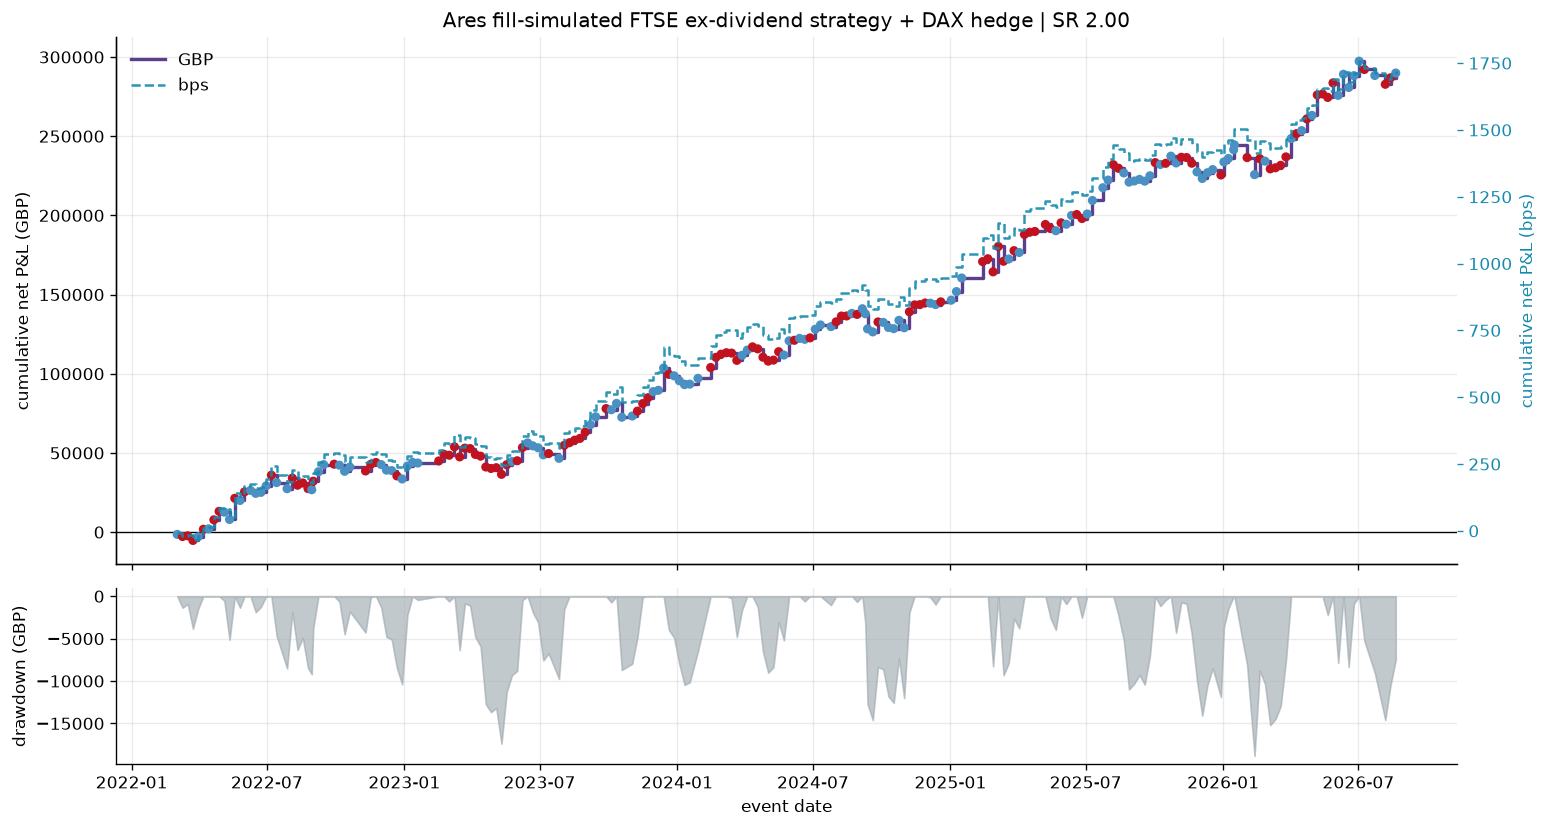

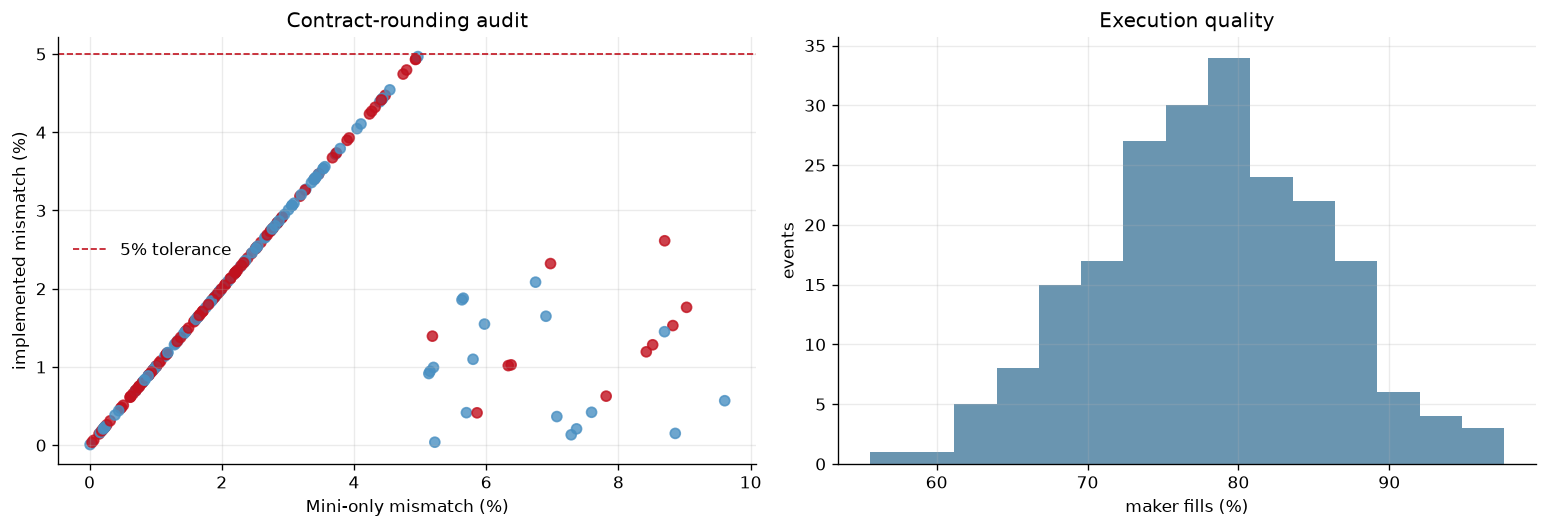

,date,direction,drop_bps,beta_60,eurgbp_entry,eurgbp_exit,fx_contract,ftse_lots,ftse_entry,ftse_exit,...,ftse_fees_gbp,dax_gross_gbp,dax_fees_gbp,gross_gbp,fees_gbp,net_gbp,net_bps,maker_pct,n_fills,closed
194,2026-03-26,short,12.234400,0.513124,0.866142,0.866327,J26,20,10052.875,10003.825,...,20.0,-4461.584978,2.771951,5348.415022,22.771951,5325.643071,26.488159,80.555556,36,True
195,2026-04-02,long,0.690753,0.581830,0.872523,0.873310,J26,20,10300.250,10374.350,...,20.0,-3239.979548,3.491667,11580.020452,23.491667,11556.528785,56.098293,76.190476,42,True
196,2026-04-09,short,14.034891,0.582840,0.870885,0.870892,J26,20,10658.875,10593.600,...,20.0,-9936.876935,3.483553,3118.123065,23.483553,3094.639512,14.516727,71.739130,46,True
197,2026-04-16,long,4.209558,0.581058,0.870686,0.871102,K26,20,10581.275,10581.375,...,20.0,1942.558028,3.483577,1962.558028,23.483577,1939.074451,9.162764,82.608696,46,True
198,2026-04-23,short,9.375568,0.560554,0.868449,0.867484,K26,20,10435.975,10403.825,...,20.0,984.594009,3.124679,7414.594009,23.124679,7391.469330,35.413410,82.500000,40,True
199,2026-04-30,long,0.231191,0.572983,0.866808,0.866754,K26,20,10212.925,10269.150,...,20.0,-8992.577125,3.120412,2252.422875,23.120412,2229.302463,10.914123,85.714286,42,True
200,2026-05-07,short,7.005929,0.556140,0.864191,0.864539,K26,20,10456.250,10374.825,...,20.0,-3345.765857,3.111714,12939.234143,23.111714,12916.122429,61.762689,82.926829,41,True
201,2026-05-14,short,19.277163,0.557833,0.866378,0.866272,K26,20,10339.800,10361.300,...,20.0,4937.751479,3.118771,637.751479,23.118771,614.632708,2.972169,84.210526,38,True
202,2026-05-21,short,9.294499,0.570787,0.865895,0.866091,M26,20,10394.300,10436.225,...,20.0,6201.211806,3.117575,-2183.788194,23.117575,-2206.905769,-10.615942,90.476190,42,True
203,2026-05-28,short,10.037118,0.595321,0.866844,0.867384,M26,20,10454.100,10425.000,...,20.0,3365.450882,3.121612,9185.450882,23.121612,9162.329271,43.821703,72.500000,40,True


In [5]:
colors = closed["direction"].map({"long": "#4a90c2", "short": "#c1121f"})
cum = closed["net_gbp"].cumsum()
cum_bps = closed["net_bps"].cumsum()
drawdown = cum - cum.cummax()

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})
gbp_line, = axes[0].step(closed["date"], cum, where="post",
                         color="#5b3f8c", lw=2, label="GBP")
axes[0].scatter(closed["date"], cum, c=colors, s=20, zorder=3)
axes[0].axhline(0, color="black", lw=.8)
axes[0].set(title=("Ares fill-simulated FTSE ex-dividend strategy + DAX hedge | "
                   f"SR {event_sharpe(results):.2f}"),
            ylabel="cumulative net P&L (GBP)")
bps_ax = axes[0].twinx()
bps_line, = bps_ax.step(closed["date"], cum_bps, where="post",
                        color="#168aad", lw=1.5, ls="--", alpha=.9,
                        label="bps")
bps_ax.set_ylabel("cumulative net P&L (bps)", color="#168aad")
bps_ax.tick_params(axis="y", colors="#168aad")
bps_ax.grid(False)
axes[0].legend(handles=[gbp_line, bps_line], loc="upper left", frameon=False)
axes[1].fill_between(closed["date"], drawdown, 0, color="#9aa5ad", alpha=.6)
axes[1].set(ylabel="drawdown (GBP)", xlabel="event date")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(closed["mini_only_error_pct"], closed["hedge_error_pct"],
                c=colors, alpha=.8)
axes[0].axhline(5, color="#c1121f", ls="--", lw=1, label="5% tolerance")
axes[0].set(xlabel="Mini-only mismatch (%)", ylabel="implemented mismatch (%)",
            title="Contract-rounding audit")
axes[0].legend(frameon=False)
axes[1].hist(closed["maker_pct"], bins=15, color="#457b9d", alpha=.8)
axes[1].set(xlabel="maker fills (%)", ylabel="events", title="Execution quality")
fig.tight_layout()
plt.show()

display(closed.tail(20))

## 4. Fill prices versus crossing at the scheduled endpoints

This section separates execution into two effects for FTSE and the DAX family:

1. **Spread capture**: the actual fill versus crossing the BBO visible when the
   fill reached the strategy. Positive values mean passive execution beat crossing.
2. **Waiting/timing**: movement in the executable BBO between the scheduled
   endpoint and the fill. Positive values mean waiting helped.

Their sum is the actual fill advantage versus crossing immediately at 08:00 for
entry and 10:00 for exit. Entry references are the first fully tradable snapshots
at or immediately after 08:00; exit references are captured at 10:00. DAX means
FDAX, Mini-DAX and Micro-DAX, translated to GBP using their contract point values.

In [6]:
EXECUTION_TABLE_ROWS = 25
POINT_VALUE = {"FT": 10.0, "DAX": 25.0, "FDXM": 5.0, "FDXS": 1.0}

execution_fills = pd.read_csv(
    HEDGED_DIR / "execution_fills.csv", parse_dates=["ts", "date"])
execution_refs = pd.read_csv(
    HEDGED_DIR / "execution_references.csv", parse_dates=["ts", "date"])

if execution_fills.empty or execution_refs.empty:
    raise ValueError("Execution diagnostics are empty; rerun the Ares simulation cell")

event_info = results[["date", "direction", "eurgbp_entry", "eurgbp_exit"]]
execution_fills = execution_fills.merge(event_info, on="date", how="left", validate="many_to_one")
execution_fills["asset_group"] = np.where(execution_fills["asset"].eq("FT"), "FTSE", "DAX")

ft_entry = ((execution_fills["direction"].eq("long") & execution_fills["side"].eq("BUY")) |
            (execution_fills["direction"].eq("short") & execution_fills["side"].eq("SELL")))
dax_entry = ((execution_fills["direction"].eq("long") & execution_fills["side"].eq("SELL")) |
             (execution_fills["direction"].eq("short") & execution_fills["side"].eq("BUY")))
execution_fills["phase"] = np.where(
    np.where(execution_fills["asset"].eq("FT"), ft_entry, dax_entry), "entry", "exit")

refs = execution_refs.rename(columns={
    "ts": "reference_ts", "bid": "reference_bid", "ask": "reference_ask",
    "mid": "reference_mid",
})
execution_fills = execution_fills.merge(
    refs[["date", "phase", "asset", "reference_ts", "reference_bid",
          "reference_ask", "reference_mid"]],
    on=["date", "phase", "asset"], how="left", validate="many_to_one")

entry_mid = refs.loc[refs["phase"].eq("entry"), ["date", "asset", "reference_mid"]]
entry_mid = entry_mid.rename(columns={"reference_mid": "mid_0800"})
execution_fills = execution_fills.merge(
    entry_mid, on=["date", "asset"], how="left", validate="many_to_one")

buy = execution_fills["side"].eq("BUY")
side_sign = np.where(buy, -1.0, 1.0)  # positive means a better execution
execution_fills["scheduled_cross"] = np.where(
    buy, execution_fills["reference_ask"], execution_fills["reference_bid"])
execution_fills["observed_cross"] = np.where(
    buy, execution_fills["observed_ask"], execution_fills["observed_bid"])
execution_fills["vs_0800_mid_points"] = (
    side_sign * (execution_fills["price"] - execution_fills["mid_0800"]))
execution_fills["actual_vs_cross_points"] = (
    side_sign * (execution_fills["price"] - execution_fills["scheduled_cross"]))
execution_fills["spread_capture_points"] = (
    side_sign * (execution_fills["price"] - execution_fills["observed_cross"]))
execution_fills["waiting_timing_points"] = (
    execution_fills["actual_vs_cross_points"] - execution_fills["spread_capture_points"])
execution_fills["seconds_from_reference"] = (
    execution_fills["ts"] - execution_fills["reference_ts"]).dt.total_seconds()
execution_fills["point_value"] = execution_fills["asset"].map(POINT_VALUE)
# Ares translates the complete DAX round trip at the event's exit EURGBP rate.
execution_fills["gbp_per_native"] = np.where(
    execution_fills["asset"].eq("FT"), 1.0, execution_fills["eurgbp_exit"])
execution_fills["gbp_multiplier"] = (
    execution_fills["qty"] * execution_fills["point_value"]
    * execution_fills["gbp_per_native"])
for source, target in [
    ("actual_vs_cross_points", "actual_vs_cross_gbp"),
    ("spread_capture_points", "spread_capture_gbp"),
    ("waiting_timing_points", "waiting_timing_gbp"),
]:
    execution_fills[target] = execution_fills[source] * execution_fills["gbp_multiplier"]

execution_fills["fill_notional"] = execution_fills["price"] * execution_fills["qty"]
execution_fills["observed_cross_notional"] = (
    execution_fills["observed_cross"] * execution_fills["qty"])
execution_fills["maker_qty"] = execution_fills["is_maker"] * execution_fills["qty"]

order_keys = ["date", "asset_group", "asset", "contract", "phase", "side", "order_id"]
order_execution = execution_fills.groupby(order_keys, as_index=False).agg(
    first_fill=("ts", "min"), last_fill=("ts", "max"), qty=("qty", "sum"),
    fill_notional=("fill_notional", "sum"), maker_qty=("maker_qty", "sum"),
    mid_0800=("mid_0800", "first"), scheduled_cross=("scheduled_cross", "first"),
    observed_cross_notional=("observed_cross_notional", "sum"),
    seconds_from_reference=("seconds_from_reference", "mean"),
    actual_vs_cross_gbp=("actual_vs_cross_gbp", "sum"),
    spread_capture_gbp=("spread_capture_gbp", "sum"),
    waiting_timing_gbp=("waiting_timing_gbp", "sum"),
)
order_execution["fill_vwap"] = order_execution["fill_notional"] / order_execution["qty"]
order_execution["observed_cross_vwap"] = (
    order_execution["observed_cross_notional"] / order_execution["qty"])
order_execution["maker_pct"] = order_execution["maker_qty"] / order_execution["qty"] * 100
order_execution = order_execution.drop(columns=[
    "fill_notional", "maker_qty", "observed_cross_notional"])

def execution_event_row(key, frame):
    day, asset_group = key
    row = {"date": day, "asset_group": asset_group,
           "orders": frame["order_id"].nunique(), "fills": len(frame),
           "maker_pct": np.average(frame["is_maker"] * 100, weights=frame["qty"]),
           "spread_capture_gbp": frame["spread_capture_gbp"].sum(),
           "waiting_timing_gbp": frame["waiting_timing_gbp"].sum(),
           "actual_vs_cross_gbp": frame["actual_vs_cross_gbp"].sum()}
    cash_sign = np.where(frame["side"].eq("SELL"), 1.0, -1.0)
    row["actual_gross_gbp"] = np.sum(
        cash_sign * frame["price"] * frame["gbp_multiplier"])
    row["scheduled_cross_gross_gbp"] = np.sum(
        cash_sign * frame["scheduled_cross"] * frame["gbp_multiplier"])
    for phase in ("entry", "exit"):
        leg = frame[frame["phase"].eq(phase)]
        weights = leg["qty"] * leg["point_value"]
        row[f"{phase}_vwap"] = np.average(leg["price"], weights=weights)
        row[f"{phase}_scheduled_cross"] = np.average(
            leg["scheduled_cross"], weights=weights)
        row[f"{phase}_mean_seconds_from_reference"] = np.average(
            leg["seconds_from_reference"], weights=weights)
    return row

event_execution = pd.DataFrame([
    execution_event_row(key, frame)
    for key, frame in execution_fills.groupby(["date", "asset_group"], sort=True)
]).sort_values(["date", "asset_group"]).reset_index(drop=True)

execution_summary = event_execution.groupby("asset_group").agg(
    events=("date", "size"), orders=("orders", "sum"), fills=("fills", "sum"),
    actual_gross_gbp=("actual_gross_gbp", "sum"),
    crossing_gross_gbp=("scheduled_cross_gross_gbp", "sum"),
    spread_capture_gbp=("spread_capture_gbp", "sum"),
    waiting_timing_gbp=("waiting_timing_gbp", "sum"),
    actual_vs_cross_gbp=("actual_vs_cross_gbp", "sum"),
    mean_event_vs_cross_gbp=("actual_vs_cross_gbp", "mean"),
    median_event_vs_cross_gbp=("actual_vs_cross_gbp", "median"),
    maker_pct=("maker_pct", "mean"),
)
display(execution_summary.round(2))

order_columns = [
    "date", "asset", "contract", "phase", "side", "order_id", "first_fill", "qty",
    "fill_vwap", "mid_0800", "scheduled_cross", "observed_cross_vwap", "maker_pct",
    "seconds_from_reference", "spread_capture_gbp", "waiting_timing_gbp",
    "actual_vs_cross_gbp",
]
for asset_group in ("FTSE", "DAX"):
    print(f"{asset_group}: {EXECUTION_TABLE_ROWS} orders with the worst result versus endpoint crossing")
    display(order_execution.loc[order_execution["asset_group"].eq(asset_group), order_columns]
            .nsmallest(EXECUTION_TABLE_ROWS, "actual_vs_cross_gbp"))

,events,orders,fills,actual_gross_gbp,crossing_gross_gbp,spread_capture_gbp,waiting_timing_gbp,actual_vs_cross_gbp,mean_event_vs_cross_gbp,median_event_vs_cross_gbp,maker_pct
asset_group,,,,,,,,,,,
DAX,214,1646,1646,3179.38,1013.98,29608.84,-27443.45,2165.4,10.12,40.02,76.30
FTSE,214,4631,7309,291640.00,297200.00,45635.00,-51195.00,-5560.0,-25.98,-47.50,72.94


FTSE: 25 orders with the worst result versus endpoint crossing


,date,asset,contract,phase,side,order_id,first_fill,qty,fill_vwap,mid_0800,scheduled_cross,observed_cross_vwap,maker_pct,seconds_from_reference,spread_capture_gbp,waiting_timing_gbp,actual_vs_cross_gbp
5602,2026-02-26,FT,FTH26,entry,BUY,5617,2026-02-26 08:00:16.532589,2,10817.0,10781.00,10781.5,10819.00,100.0,16.580078,40.0,-750.0,-710.0
5603,2026-02-26,FT,FTH26,entry,BUY,5618,2026-02-26 08:00:17.179530,2,10811.5,10781.00,10781.5,10812.75,100.0,17.241600,25.0,-625.0,-600.0
5601,2026-02-26,FT,FTH26,entry,BUY,5612,2026-02-26 08:00:10.655807,2,10811.0,10781.00,10781.5,10813.00,100.0,10.655915,40.0,-630.0,-590.0
5604,2026-02-26,FT,FTH26,entry,BUY,5619,2026-02-26 08:00:18.590396,2,10810.5,10781.00,10781.5,10812.00,100.0,18.590396,30.0,-610.0,-580.0
5605,2026-02-26,FT,FTH26,entry,BUY,5620,2026-02-26 08:00:20.259061,2,10809.5,10781.00,10781.5,10811.00,100.0,20.259061,30.0,-590.0,-560.0
5606,2026-02-26,FT,FTH26,entry,BUY,5622,2026-02-26 08:00:22.037514,2,10808.0,10781.00,10781.5,10809.50,100.0,22.354571,30.0,-560.0,-530.0
2621,2024-01-04,FT,FTH24,entry,BUY,2217,2024-01-04 08:00:30.107808,2,7714.0,7688.75,7689.0,7715.00,100.0,30.107808,20.0,-520.0,-500.0
134,2022-03-31,FT,FTM22,entry,BUY,34,2022-03-31 07:00:34.658429,2,7550.0,7526.00,7526.5,7551.00,100.0,34.658429,20.0,-490.0,-470.0
135,2022-03-31,FT,FTM22,entry,BUY,36,2022-03-31 07:00:36.192986,2,7550.0,7526.00,7526.5,7550.25,50.0,36.228607,5.0,-475.0,-470.0
136,2022-03-31,FT,FTM22,entry,BUY,38,2022-03-31 07:00:38.515251,2,7550.0,7526.00,7526.5,7551.50,100.0,38.544480,30.0,-500.0,-470.0


DAX: 25 orders with the worst result versus endpoint crossing


,date,asset,contract,phase,side,order_id,first_fill,qty,fill_vwap,mid_0800,scheduled_cross,observed_cross_vwap,maker_pct,seconds_from_reference,spread_capture_gbp,waiting_timing_gbp,actual_vs_cross_gbp
5618,2026-03-05,DAX,DAXH26,exit,SELL,5712,2026-03-05 09:55:09.292221,1,24240.0,24154.0,24290.0,24235.0,100.0,-290.707779,108.837377,-1197.211146,-1088.373769
4741,2025-07-03,DAX,DAXU25,exit,BUY,7695,2025-07-03 08:55:09.952410,1,23947.0,23998.0,23919.0,23949.0,100.0,-290.047590,43.357961,-650.369409,-607.011448
6052,2026-06-18,DAX,DAXU26,exit,BUY,9935,2026-06-18 08:56:07.700000,1,25062.0,25162.0,25035.0,25062.0,0.0,-232.300000,0.000000,-585.738958,-585.738958
1443,2023-03-16,DAX,DAXM23,exit,SELL,1382,2023-03-16 09:55:08.095550,1,14953.0,15116.0,14979.0,14953.0,0.0,-291.904450,0.000000,-573.550740,-573.550740
6219,2026-08-13,DAX,DAXU26,entry,BUY,10382,2026-08-13 07:00:02.470880,1,26543.0,26515.5,26517.0,26547.0,100.0,2.470880,85.503376,-641.275317,-555.771942
61,2022-03-17,DAX,DAXH22,exit,SELL,153,2022-03-17 09:55:02.578988,1,14381.0,14511.0,14407.0,14380.0,100.0,-297.421012,21.056454,-568.524268,-547.467814
457,2022-06-16,DAX,DAXM22,exit,BUY,887,2022-06-16 08:55:07.798296,1,13182.0,13448.5,13157.0,13182.0,0.0,-292.201704,0.000000,-538.992714,-538.992714
964,2022-10-20,DAX,DAXZ22,exit,BUY,2065,2022-10-20 08:55:00.301998,1,12675.0,12718.0,12651.0,12676.0,100.0,-299.698002,21.928434,-548.210858,-526.282423
2250,2023-10-05,DAX,DAXZ23,entry,SELL,3942,2023-10-05 07:00:08.549287,1,15213.0,15238.0,15237.0,15211.0,100.0,8.549287,43.439987,-564.719828,-521.279842
6135,2026-07-09,DAX,DAXU26,entry,BUY,10113,2026-07-09 07:00:05.232652,1,25229.0,25204.0,25205.0,25232.0,100.0,5.232652,63.897898,-575.081078,-511.183181


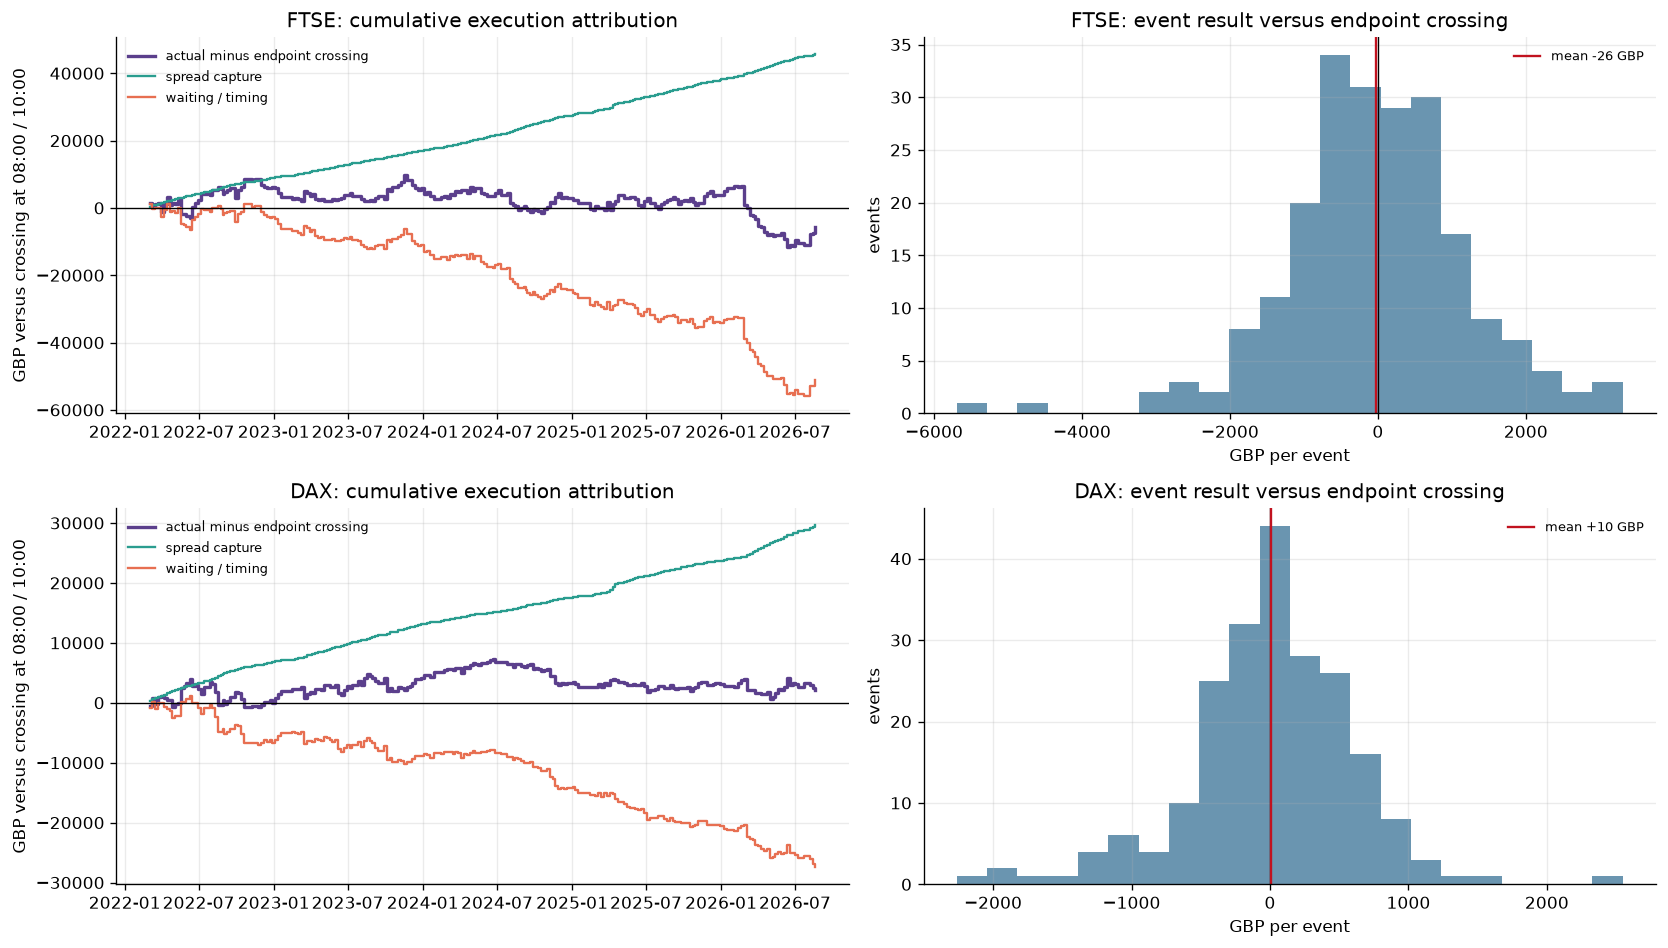

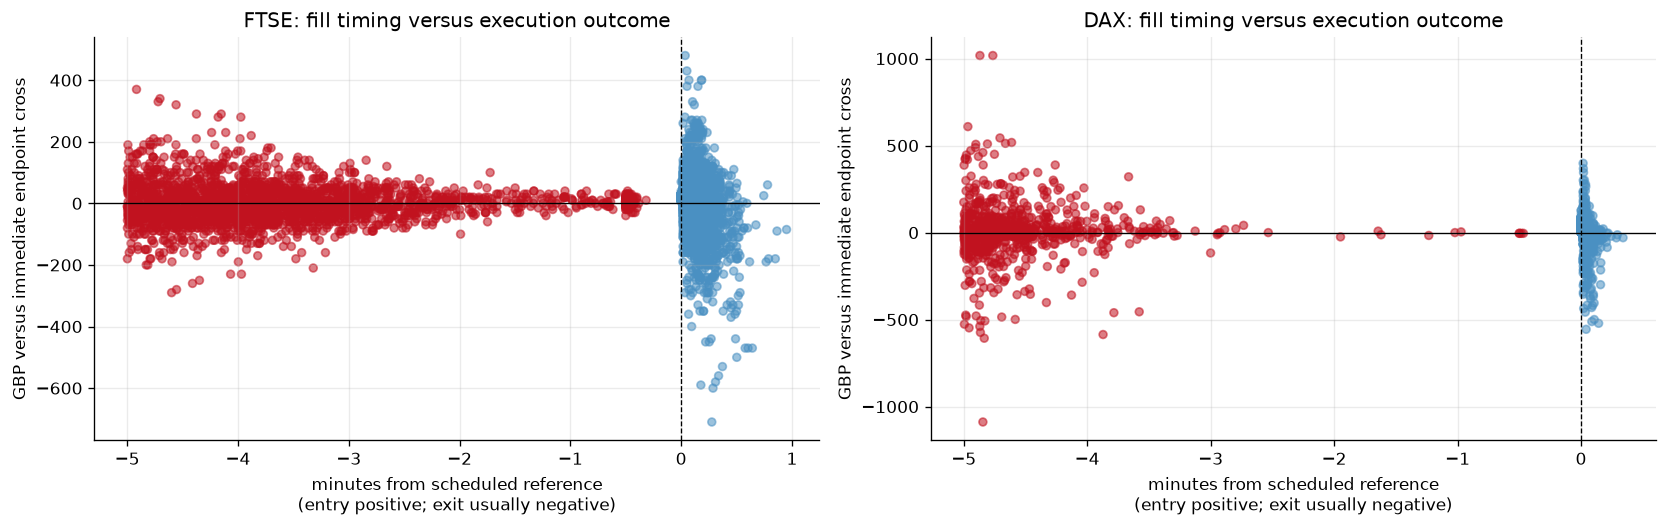

,date,asset_group,orders,fills,maker_pct,spread_capture_gbp,waiting_timing_gbp,actual_vs_cross_gbp,actual_gross_gbp,scheduled_cross_gross_gbp,entry_vwap,entry_scheduled_cross,entry_mean_seconds_from_reference,exit_vwap,exit_scheduled_cross,exit_mean_seconds_from_reference
381,2026-02-26,FTSE,20,32,85.0,405.000000,-6095.000000,-5690.000000,-990.000000,4700.000000,10805.400000,10781.500000,11.955121,10800.450000,10805.000000,-221.996263
23,2022-05-19,FTSE,23,39,85.0,235.000000,-4720.000000,-4485.000000,17715.000000,22200.000000,7365.400000,7375.500000,9.960099,7276.825000,7264.500000,-246.700949
229,2024-08-01,FTSE,21,32,60.0,305.000000,-3505.000000,-3200.000000,8000.000000,11200.000000,8385.900000,8394.500000,13.274117,8345.900000,8338.500000,-276.696345
59,2022-09-29,FTSE,21,38,80.0,270.000000,-3180.000000,-2910.000000,10790.000000,13700.000000,6964.000000,6978.000000,9.855814,6910.050000,6909.500000,-273.046153
9,2022-03-31,FTSE,22,37,82.5,270.000000,-2770.000000,-2500.000000,-600.000000,1900.000000,7539.475000,7526.500000,17.674978,7536.475000,7536.000000,-237.240327
411,2026-06-11,FTSE,22,31,40.0,180.000000,-2655.000000,-2475.000000,12125.000000,14600.000000,10256.125000,10244.500000,9.319811,10316.750000,10317.500000,-221.275446
15,2022-04-21,FTSE,21,33,65.0,170.000000,-2635.000000,-2465.000000,535.000000,3000.000000,7598.175000,7609.500000,18.840906,7595.500000,7594.500000,-242.062509
293,2025-04-03,FTSE,22,34,65.0,225.000000,-2550.000000,-2325.000000,3475.000000,5800.000000,8490.300000,8487.000000,7.386158,8507.675000,8516.000000,-246.320582
46,2022-08-18,DAX,10,10,90.0,202.830713,-2463.548036,-2260.717323,1331.076554,3591.793877,13640.529412,13625.000000,3.273446,13659.058824,13675.000000,-271.172302
385,2026-03-12,FTSE,21,29,47.5,200.000000,-2285.000000,-2085.000000,-4685.000000,-2600.000000,10295.275000,10305.500000,10.450467,10318.700000,10318.500000,-260.937706


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row_no, asset_group in enumerate(("FTSE", "DAX")):
    frame = event_execution[event_execution["asset_group"].eq(asset_group)].sort_values("date")
    ax = axes[row_no, 0]
    ax.step(frame["date"], frame["actual_vs_cross_gbp"].cumsum(), where="post",
            lw=2, color="#5b3f8c", label="actual minus endpoint crossing")
    ax.step(frame["date"], frame["spread_capture_gbp"].cumsum(), where="post",
            lw=1.4, color="#2a9d8f", label="spread capture")
    ax.step(frame["date"], frame["waiting_timing_gbp"].cumsum(), where="post",
            lw=1.4, color="#e76f51", label="waiting / timing")
    ax.axhline(0, color="black", lw=.8)
    ax.set(title=f"{asset_group}: cumulative execution attribution",
           ylabel="GBP versus crossing at 08:00 / 10:00")
    ax.legend(frameon=False, fontsize=8)

    ax = axes[row_no, 1]
    ax.hist(frame["actual_vs_cross_gbp"], bins=22, color="#457b9d", alpha=.8)
    ax.axvline(0, color="black", lw=.8)
    ax.axvline(frame["actual_vs_cross_gbp"].mean(), color="#c1121f", lw=1.4,
               label=f"mean {frame['actual_vs_cross_gbp'].mean():+.0f} GBP")
    ax.set(title=f"{asset_group}: event result versus endpoint crossing",
           xlabel="GBP per event", ylabel="events")
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, asset_group in zip(axes, ("FTSE", "DAX")):
    frame = order_execution[order_execution["asset_group"].eq(asset_group)]
    colors = frame["phase"].map({"entry": "#4a90c2", "exit": "#c1121f"})
    ax.scatter(frame["seconds_from_reference"] / 60,
               frame["actual_vs_cross_gbp"], c=colors, alpha=.55, s=22)
    ax.axhline(0, color="black", lw=.8)
    ax.axvline(0, color="black", lw=.8, ls="--")
    ax.set(title=f"{asset_group}: fill timing versus execution outcome",
           xlabel="minutes from scheduled reference\n(entry positive; exit usually negative)",
           ylabel="GBP versus immediate endpoint cross")
fig.tight_layout()
plt.show()

display(event_execution.sort_values("actual_vs_cross_gbp").head(30))